
# Phase 3: Feature Engineering

## Step 1: Load Processed Data

Load the cleaned and sales-focused datasets saved during Phase 2.


In [3]:
import pandas as pd
from pathlib import Path

# Path to the processed data folder
DATA_DIR = Path("../data/processed")

# Load both datasets
df_clean = pd.read_csv(
    DATA_DIR / "online_retail_clean.csv",
    parse_dates=["InvoiceDate"]
)


df_sales = pd.read_csv(
    DATA_DIR / "online_retail_sales.csv",
    parse_dates=["InvoiceDate"]
)

print("Clean dataset shape:", df_clean.shape)
print("Sales dataset shape:", df_sales.shape)

display(df_sales.head())

Clean dataset shape: (1033036, 8)
Sales dataset shape: (1007912, 14)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancellationInvoice,IsBadDebtAdjustment,IsZeroPrice,IsNegativeQuantity,LineValue,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,False,False,False,83.4,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,False,False,81.0,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,False,False,81.0,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,False,False,False,100.8,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,False,False,False,30.0,30.0


In [4]:
df_sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 1007912 entries, 0 to 1007911
Data columns (total 14 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   Invoice                1007912 non-null  int64         
 1   StockCode              1007912 non-null  str           
 2   Description            1007912 non-null  str           
 3   Quantity               1007912 non-null  int64         
 4   InvoiceDate            1007912 non-null  datetime64[us]
 5   Price                  1007912 non-null  float64       
 6   Customer ID            779425 non-null   float64       
 7   Country                1007912 non-null  str           
 8   IsCancellationInvoice  1007912 non-null  bool          
 9   IsBadDebtAdjustment    1007912 non-null  bool          
 10  IsZeroPrice            1007912 non-null  bool          
 11  IsNegativeQuantity     1007912 non-null  bool          
 12  LineValue              1007912 non-null

In [4]:
print("InvoiceDate dtype:", df_sales["InvoiceDate"].dtype)
print("Quantity dtype:", df_sales["Quantity"].dtype)
print("Price dtype:", df_sales["Price"].dtype)
print("Customer ID dtype:", df_sales["Customer ID"].dtype)

InvoiceDate dtype: datetime64[us]
Quantity dtype: int64
Price dtype: float64
Customer ID dtype: float64



## Step 2: Date Feature Engineering

Extract year, month, year-month, day, and weekday from InvoiceDate to support time-based sales analysis.


In [5]:
df_sales["Year"] = df_sales["InvoiceDate"].dt.year
df_sales["Month"] = df_sales["InvoiceDate"].dt.month

df_sales["YearMonth"] = (
    df_sales["InvoiceDate"].dt.to_period("M")
)

df_sales["Day"] = df_sales["InvoiceDate"].dt.day

df_sales["DayOfWeek"] = (
    df_sales["InvoiceDate"].dt.day_name()
)

# Display the new features
display(
    df_sales[
        [
            "InvoiceDate",
            "Year",
            "Month",
            "YearMonth",
            "Day",
            "DayOfWeek"
        ]
    ].tail(10)
)

,InvoiceDate,Year,Month,YearMonth,Day,DayOfWeek
1007902,2011-12-09 12:50:00,2011,12,2011-12,9,Friday
1007903,2011-12-09 12:50:00,2011,12,2011-12,9,Friday
1007904,2011-12-09 12:50:00,2011,12,2011-12,9,Friday
1007905,2011-12-09 12:50:00,2011,12,2011-12,9,Friday
1007906,2011-12-09 12:50:00,2011,12,2011-12,9,Friday
1007907,2011-12-09 12:50:00,2011,12,2011-12,9,Friday
1007908,2011-12-09 12:50:00,2011,12,2011-12,9,Friday
1007909,2011-12-09 12:50:00,2011,12,2011-12,9,Friday
1007910,2011-12-09 12:50:00,2011,12,2011-12,9,Friday
1007911,2011-12-09 12:50:00,2011,12,2011-12,9,Friday


In [6]:
print("Years:", sorted(df_sales["Year"].unique()))
print("Months:", sorted(df_sales["Month"].unique()))
print("Weekdays:", df_sales["DayOfWeek"].nunique())

print("Missing YearMonth values:", df_sales["YearMonth"].isna().sum())

display(
    df_sales["YearMonth"]
    .value_counts()
    .sort_index()
    .head(10)
)

Years: [np.int32(2009), np.int32(2010), np.int32(2011)]
Months: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]
Weekdays: 7
Missing YearMonth values: 0


YearMonth
2009-12    43453
2010-01    30317
2010-02    27952
2010-03    39841
2010-04    32858
2010-05    33383
2010-06    38391
2010-07    32112
2010-08    32109
2010-09    40630
Freq: M, Name: count, dtype: int64


## Step 3: Monthly Sales Analysis

Aggregate transaction data by month to calculate revenue, units sold, and unique invoices.


In [7]:
monthly_sales = (
    df_sales.groupby("YearMonth")
    .agg(
        Total_Revenue=("Revenue","sum"),
        Total_Units=("Quantity","sum"),
        Unique_Invoices=("Invoice","nunique"),
        Average_Line_Revenue=("Revenue","mean"),
    )
    .reset_index()
)

display(monthly_sales.head(10))

,YearMonth,Total_Revenue,Total_Units,Unique_Invoices,Average_Line_Revenue
0,2009-12,822483.950,425461,1682,18.928128
1,2010-01,651155.112,390672,1105,21.478217
2,2010-02,551504.726,381879,1201,19.730421
3,2010-03,830915.261,526026,1681,20.855783
4,2010-04,678875.252,366705,1462,20.660882
5,2010-05,657705.500,395868,1500,19.701809
6,2010-06,749537.310,406820,1645,19.523777
7,2010-07,648810.270,337895,1529,20.204605
8,2010-08,695251.910,472380,1425,21.652867
9,2010-09,921696.991,583864,1839,22.685134


In [8]:
# Month with the highest revenue
best_month = monthly_sales.loc[
    monthly_sales["Total_Revenue"].idxmax()
]

# Month with the lowest revenue
worst_month = monthly_sales.loc[
    monthly_sales["Total_Revenue"].idxmin()
]

print("Highest-revenue month:")
display(best_month)

print("Lowest-revenue month:")
display(worst_month)

Highest-revenue month:


YearMonth                  2011-11
Total_Revenue           1503866.78
Total_Units                 751377
Unique_Invoices               2769
Average_Line_Revenue     18.338944
Name: 23, dtype: object

Lowest-revenue month:


YearMonth                 2011-02
Total_Revenue           522545.56
Total_Units                282934
Unique_Invoices              1100
Average_Line_Revenue    19.438493
Name: 14, dtype: object

## Step 4: Monthly Revenue Trend

Visualize monthly revenue to identify growth patterns, seasonal changes, and unusual peaks or drops.

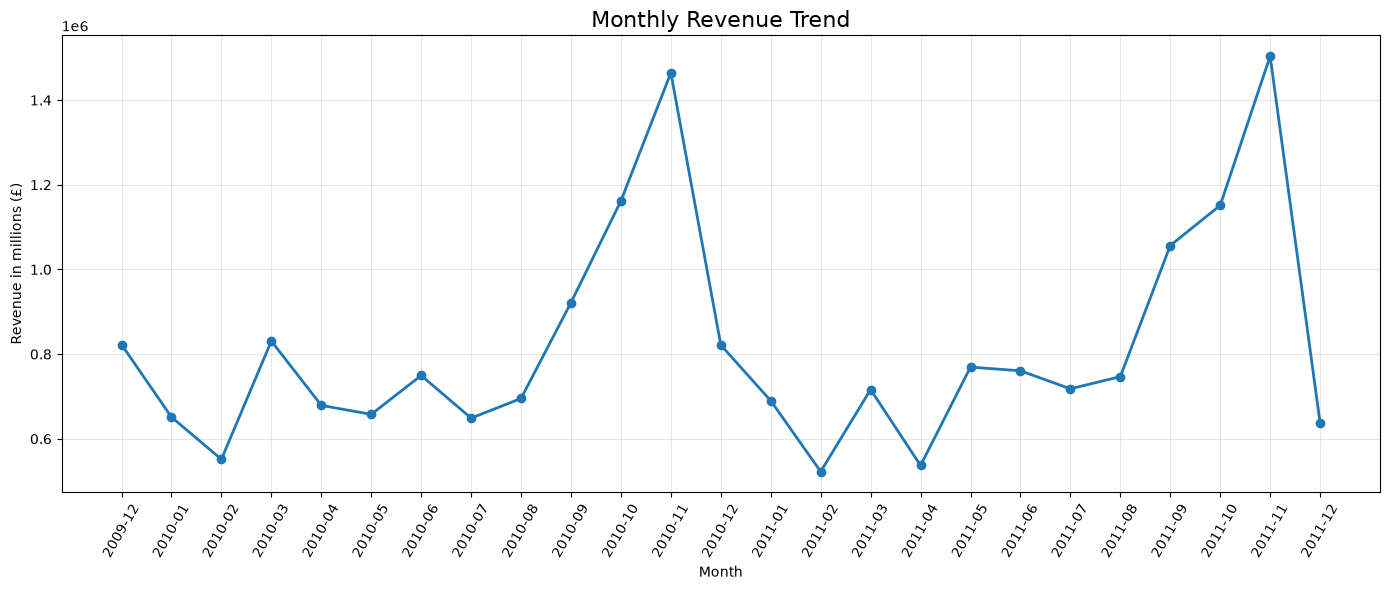

In [9]:
import matplotlib.pyplot as plt

# Convert YearMonth to strings for readable x-axis labels
monthly_sales["Month_Label"] = monthly_sales["YearMonth"].astype(str)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Month_Label"],
    monthly_sales["Total_Revenue"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue in millions (£)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

## Step 5: Month-over-Month Revenue Growth

Calculate the percentage change in revenue between consecutive months to identify significant increases and decreases.

In [10]:
monthly_sales["Previous_Month_Revenue"] = (
    monthly_sales["Total_Revenue"].shift(1)
)

monthly_sales["MoM_Growth_Percentage"] = (
    monthly_sales["Total_Revenue"]
    .pct_change()
    .mul(100)
)

display(
    monthly_sales[
        [
            "YearMonth",
            "Total_Revenue",
            "Previous_Month_Revenue",
            "MoM_Growth_Percentage"
        ]
    ].head(12).round(2)
)

C:\Users\SAMSUNG\AppData\Local\Temp\ipykernel_27804\3650737916.py:19: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(12).round(2)


,YearMonth,Total_Revenue,Previous_Month_Revenue,MoM_Growth_Percentage
0,2009-12,822483.95,NaN,NaN
1,2010-01,651155.11,822483.95,-20.83
2,2010-02,551504.73,651155.11,-15.30
3,2010-03,830915.26,551504.73,50.66
4,2010-04,678875.25,830915.26,-18.30
5,2010-05,657705.50,678875.25,-3.12
6,2010-06,749537.31,657705.50,13.96
7,2010-07,648810.27,749537.31,-13.44
8,2010-08,695251.91,648810.27,7.16
9,2010-09,921696.99,695251.91,32.57


In [11]:
# Exclude the first month because it has no previous month
valid_growth = monthly_sales.dropna(
    subset=["MoM_Growth_Percentage"]
)

biggest_increase = valid_growth.loc[
    valid_growth["MoM_Growth_Percentage"].idxmax()
]

biggest_decrease = valid_growth.loc[
    valid_growth["MoM_Growth_Percentage"].idxmin()
]

print("Biggest month-over-month increase:")
display(biggest_increase)

print("Biggest month-over-month decrease:")
display(biggest_decrease)

Biggest month-over-month increase:


YearMonth                    2010-03
Total_Revenue             830915.261
Total_Units                   526026
Unique_Invoices                 1681
Average_Line_Revenue       20.855783
Month_Label                  2010-03
Previous_Month_Revenue    551504.726
MoM_Growth_Percentage      50.663307
Name: 3, dtype: object

Biggest month-over-month decrease:


YearMonth                    2011-12
Total_Revenue              637808.33
Total_Units                   313613
Unique_Invoices                  819
Average_Line_Revenue       25.682867
Month_Label                  2011-12
Previous_Month_Revenue    1503866.78
MoM_Growth_Percentage     -57.588775
Name: 24, dtype: object

## Step 6: Year-End Revenue Pattern

Compare monthly revenue across years to investigate possible seasonal trends. Pay special attention to October, November, and December, while accounting for incomplete months.

In [12]:
monthly_sales["Year"] = (
    monthly_sales["YearMonth"]
    .dt.year
)

In [13]:
# Extract month number
monthly_sales["Month_Number"] = (
    monthly_sales["YearMonth"].dt.month
)

# Convert Period to Timestamp, then extract month name
monthly_sales["Month_Name"] = (
    monthly_sales["YearMonth"]
    .dt.to_timestamp()
    .dt.month_name()
)

# Compare revenue for each calendar month across years
seasonal_revenue = monthly_sales.pivot(
    index="Month_Name",
    columns="Year",
    values="Total_Revenue"
)

# Arrange months in calendar order
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

seasonal_revenue = seasonal_revenue.reindex(month_order)

display(seasonal_revenue.round(2))

Year,2009,2010,2011
Month_Name,,,
January,NaN,651155.11,689811.61
February,NaN,551504.73,522545.56
March,NaN,830915.26,716215.26
April,NaN,678875.25,536968.49
May,NaN,657705.50,769296.61
June,NaN,749537.31,760547.01
July,NaN,648810.27,718076.12
August,NaN,695251.91,746779.32
September,NaN,921696.99,1056435.19


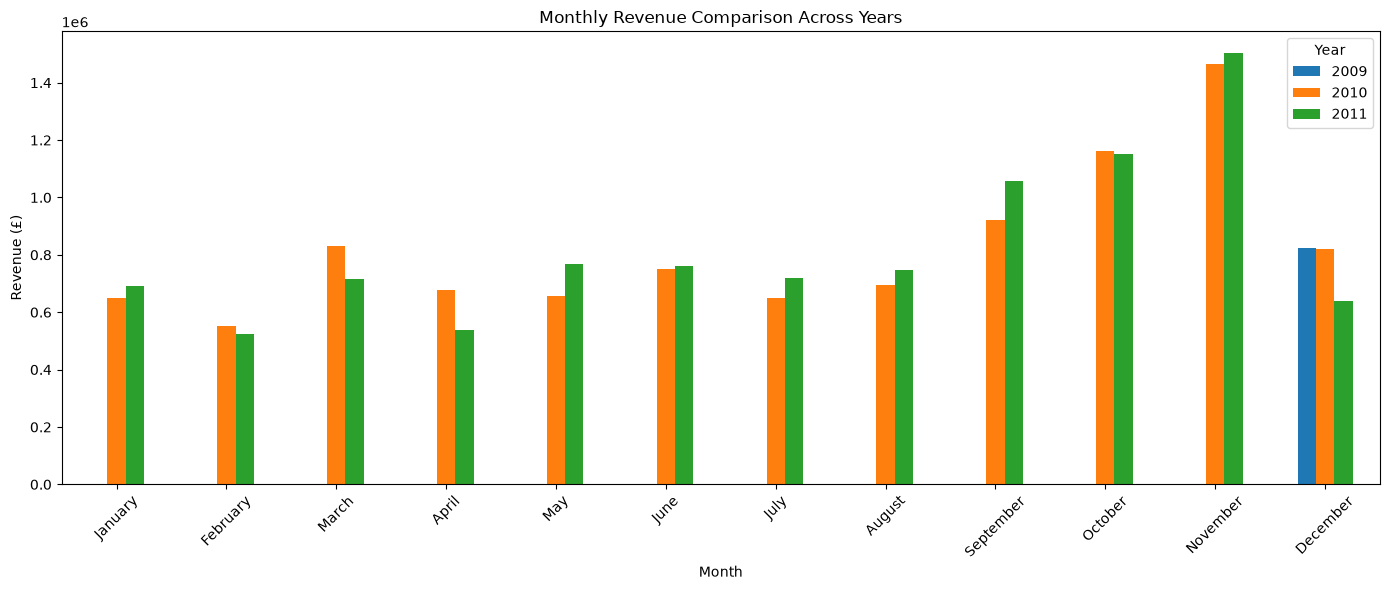

In [14]:
seasonal_revenue.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Monthly Revenue Comparison Across Years")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.legend(title="Year")
plt.tight_layout()
plt.show()

## Step 7: Product Performance Analysis

Identify the products that generate the highest revenue and understand which products contribute most to total sales.

In [15]:
product_sales = (
    df_sales.groupby(["StockCode","Description"])
    .agg(
        Total_Revenue=("Revenue","sum"),
        Total_Units_Sold=("Quantity","sum"),
        Number_of_Transactions=("Invoice","nunique")
    )
    .reset_index()
)

product_sales = product_sales.sort_values(
    "Total_Revenue",
    ascending=False
)

display(
    product_sales.head(10).round(2)
)

,StockCode,Description,Total_Revenue,Total_Units_Sold,Number_of_Transactions
5614,M,Manual,339226.24,9629,784
1891,22423,REGENCY CAKESTAND 3 TIER,330590.32,26478,3918
5613,DOT,DOTCOM POSTAGE,309854.11,1415,1415
4999,85123A,WHITE HANGING HEART T-LIGHT HOLDER,257546.20,94142,5356
3355,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
3716,47566,PARTY BUNTING,148318.28,28200,2674
4967,85099B,JUMBO BAG RED RETROSPOT,145961.83,77280,3245
4640,84879,ASSORTED COLOUR BIRD ORNAMENT,129324.49,80082,2807
5616,POST,POSTAGE,125682.42,5363,1851
1477,22086,PAPER CHAIN KIT 50'S CHRISTMAS,117760.29,35084,2018


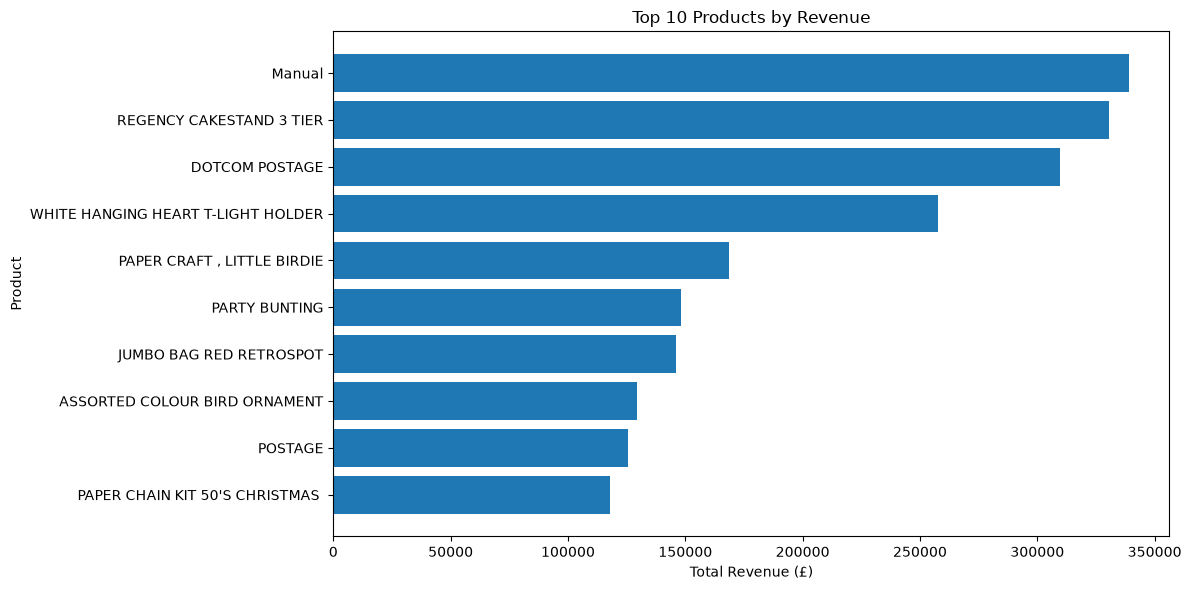

In [16]:
top_10_products = product_sales.head(10).copy()

top_10_products["Product_Label"] = (
    top_10_products["Description"]
    .fillna("Unknown")
    .str.slice(0,35)
)

plt.figure(figsize=(12, 6))

plt.barh(
    top_10_products["Product_Label"].iloc[::-1],
    top_10_products["Total_Revenue"].iloc[::-1]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

## Step 8: Refine Product Performance

Exclude postage and manual entries from the merchandise ranking, and compare the top products using revenue, units sold, and invoice count.

In [17]:
# Inspect the unusual product records first
display(
    product_sales[
        product_sales["StockCode"].astype(str).isin(
            ["M", "DOT", "POST", "PADS"]
        )
    ].round(2)
)

,StockCode,Description,Total_Revenue,Total_Units_Sold,Number_of_Transactions
5614,M,Manual,339226.24,9629,784
5613,DOT,DOTCOM POSTAGE,309854.11,1415,1415
5616,POST,POSTAGE,125682.42,5363,1851
5615,PADS,PADS TO MATCH ALL CUSHIONS,0.02,17,17


In [18]:
# Exclude known non-merchandise stock codes
non_merchandise_codes = ["M", "DOT", "POST", "PADS"]

merchandise_sales = df_sales.loc[
    ~df_sales["StockCode"].astype(str).isin(
        non_merchandise_codes
    )
].copy()

product_merchandise = (
    merchandise_sales.groupby(["StockCode", "Description"])
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Units_Sold=("Quantity", "sum"),
        Number_of_Transactions=("Invoice", "nunique")
    )
    .reset_index()
    .sort_values("Total_Revenue", ascending=False)
)

display(product_merchandise.head(10).round(2))

,StockCode,Description,Total_Revenue,Total_Units_Sold,Number_of_Transactions
1891,22423,REGENCY CAKESTAND 3 TIER,330590.32,26478,3918
4999,85123A,WHITE HANGING HEART T-LIGHT HOLDER,257546.20,94142,5356
3355,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
3716,47566,PARTY BUNTING,148318.28,28200,2674
4967,85099B,JUMBO BAG RED RETROSPOT,145961.83,77280,3245
4640,84879,ASSORTED COLOUR BIRD ORNAMENT,129324.49,80082,2807
1477,22086,PAPER CHAIN KIT 50'S CHRISTMAS,117760.29,35084,2018
2810,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
4058,79321,CHILLI LIGHTS,80540.88,15841,1135
4227,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,71300.40,31409,756


## Step 9: Country-Level Sales Analysis

Aggregate sales by country to identify the highest-revenue markets, sales volumes, and transaction activity.

In [23]:
country_sales = (
    df_sales.groupby("Country")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Units_Sold=("Quantity", "sum"),
        Unique_Invoices=("Invoice", "nunique"),
        Unique_Customers=("Customer ID", "nunique")
    )
    .reset_index()
    .sort_values("Total_Revenue", ascending=False)
)

display(
    country_sales.head(10).round(2)
)

,Country,Total_Revenue,Total_Units_Sold,Unique_Invoices,Unique_Customers
40,United Kingdom,17399134.06,9187752,36534,5350
11,EIRE,658767.31,336329,626,5
26,Netherlands,554038.09,383879,228,22
15,Germany,425019.71,225154,789,107
14,France,350456.09,271901,622,95
0,Australia,169283.46,103759,95,15
34,Spain,108332.49,50307,154,41
36,Switzerland,100685.59,52762,93,22
35,Sweden,91869.82,88633,105,19
10,Denmark,68580.69,237471,43,12


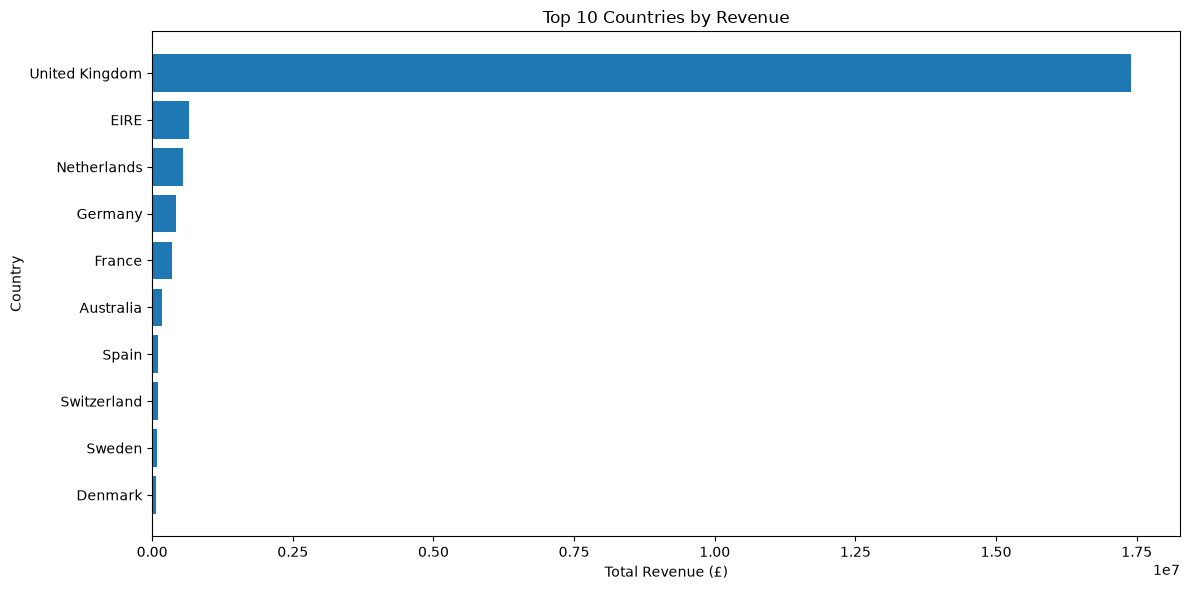

In [20]:
top_10_countries = country_sales.head(10).copy()

plt.figure(figsize=(12, 6))

plt.barh(
    top_10_countries["Country"].iloc[::-1],
    top_10_countries["Total_Revenue"].iloc[::-1]
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [24]:
total_revenue = df_sales["Revenue"].sum()

uk_revenue = country_sales.loc[
    country_sales["Country"].eq("United Kingdom"),
    "Total_Revenue"
].sum()

uk_revenue_share = (uk_revenue / total_revenue) * 100

print(f"Total revenue: £{total_revenue:,.2f}")
print(f"UK revenue: £{uk_revenue:,.2f}")
print(f"UK revenue share: {uk_revenue_share:.2f}%")

Total revenue: £20,465,198.39
UK revenue: £17,399,134.06
UK revenue share: 85.02%


In [25]:
customer_check = (
    df_sales.groupby("Country")
    .agg(
        Total_Rows=("Invoice", "size"),
        Non_Missing_Customer_IDs=("Customer ID", "count"),
        Unique_Customers=("Customer ID", "nunique")
    )
    .sort_values("Unique_Customers", ascending=False)
)

display(customer_check.head(15))

# Inspect customer IDs for EIRE
eire_customers = (
    df_sales.loc[
        df_sales["Country"].eq("EIRE"),
        "Customer ID"
    ]
    .dropna()
    .unique()
)

print("Unique non-missing EIRE customer IDs:", len(eire_customers))
print("Sample EIRE customer IDs:", eire_customers[:20])

,Total_Rows,Non_Missing_Customer_IDs,Unique_Customers
Country,,,
United Kingdom,926037,700388,5350
Germany,16432,16432,107
France,13639,13511,95
Spain,3662,3662,41
Belgium,3055,3055,29
Portugal,2470,2356,24
Switzerland,3122,3005,22
Netherlands,5085,5085,22
Sweden,1336,1317,19


Unique non-missing EIRE customer IDs: 5
Sample EIRE customer IDs: [14911. 14156. 14016. 12745. 16047.]
